## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [3]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


There were 94 survivors in the Invasive group and 98 in the Conservative group. That works out to survival rates of about 24.2% and 25.2%, so the estimated ATE is about −0.01. The difference is small, and the Invasive group’s survival rate was slightly lower, so I wouldn’t say this result shows that the pump helped.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

The code resamples the Invasive and Conservative groups separately 10,000 times. Each time, it saves both groups’ average survival rates and the difference between them.

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

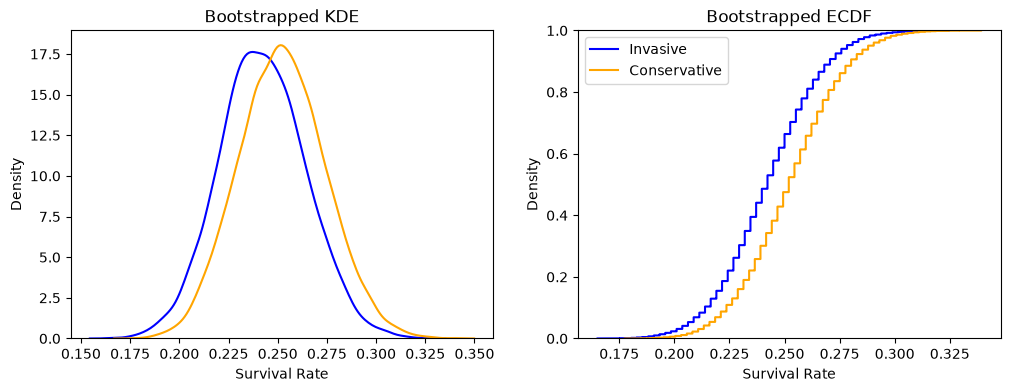

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

The two distributions overlap a lot, which suggests the groups had pretty similar survival rates. The Conservative group’s results are centered a little higher, but the difference doesn’t look very clear.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

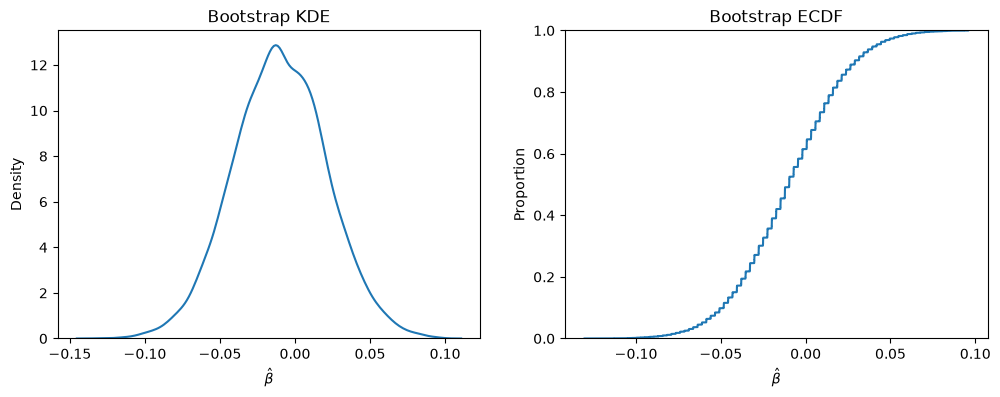

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


The ATE distribution is roughly bell-shaped and centered close to zero, around −0.01. The bootstrap estimates include both negative and positive values. The middle 90% fall between about −0.061 and 0.042.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [7]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06112024  0.04179366]
95% CI: [-0.07138314  0.05209001]
99% CI: [-0.09197526  0.07019058]


All three intervals include zero, so I’d fail to reject the idea that the effect on survival was zero at the 90%, 95%, and 99% confidence levels.

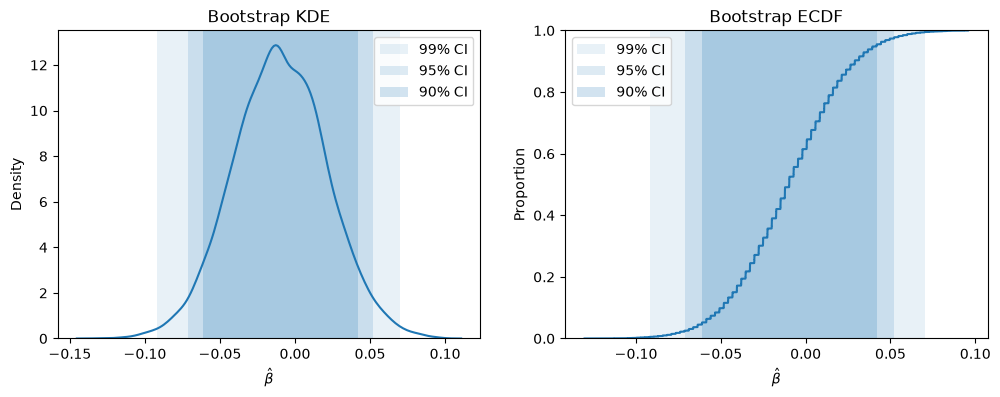

In [8]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

In this dataset, survival was slightly lower in the Invasive group, but the difference was small and all three intervals included zero. So, based on these results, there isn’t clear evidence that the intervention improved survival.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

## Compare the treatment groups

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
df = pd.read_csv("./data/diabetes.csv")

# Convert the outcome to a binary variable
df["success_rate"] = (df["outcome"].str.lower() == "success").astype(int)

print(pd.crosstab(df["treatment"], df["outcome"]))

group_summary = (
    df.groupby("treatment")["success_rate"]
    .agg(["count", "mean"])
    .rename(columns={"count": "N", "mean": "Success rate"})
)
display(group_summary.round(4))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143


,N,Success rate
treatment,,
lifestyle,234,0.5342
met,232,0.4828
rosi,233,0.6137


## Bootstrap each treatment group separately

In [10]:
R = 10_000
rng = np.random.default_rng(123)
arms = ["met", "rosi", "lifestyle"]

arm_data = {
    arm: df.loc[df["treatment"] == arm, "success_rate"].to_numpy()
    for arm in arms
}

bootstrap_means = {arm: np.empty(R) for arm in arms}

for arm in arms:
    values = arm_data[arm]

    for b in range(R):
        sample = rng.choice(values, size=len(values), replace=True)
        bootstrap_means[arm][b] = sample.mean()

boot_df = pd.DataFrame(bootstrap_means)

display(
    boot_df.agg(["mean", "std"]).T.rename(
        columns={"mean": "Mean success rate", "std": "Bootstrap SD"}
    ).round(4)
)

,Mean success rate,Bootstrap SD
met,0.4823,0.0329
rosi,0.6136,0.0320
lifestyle,0.5340,0.0329


I resampled each treatment group separately 10,000 times and calculated its success rate for every sample. The average bootstrap rates were about 48.2% for metformin, 61.4% for rosiglitazone, and 53.4% for lifestyle.

## Plot the treatment-group distributions

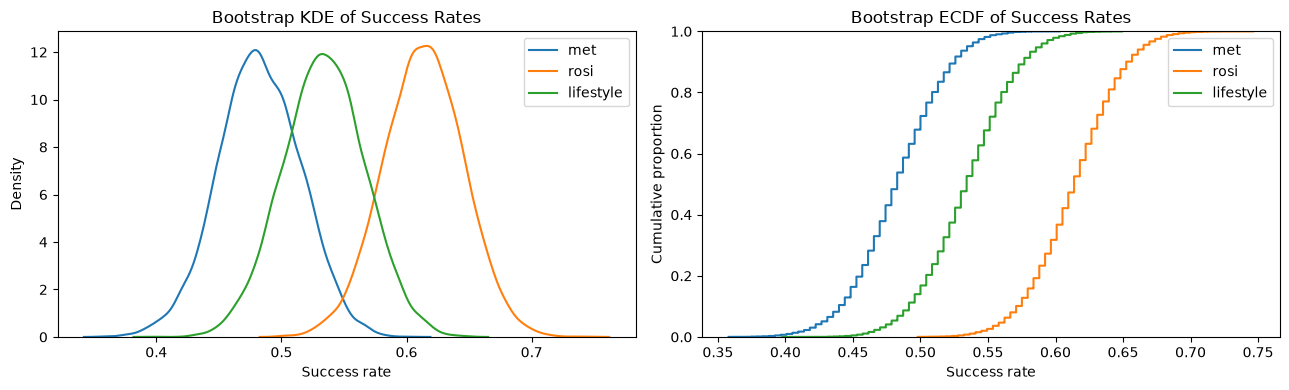

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for arm in arms:
    sns.kdeplot(bootstrap_means[arm], label=arm, ax=ax[0])
    sns.ecdfplot(bootstrap_means[arm], label=arm, ax=ax[1])

ax[0].set(
    title="Bootstrap KDE of Success Rates",
    xlabel="Success rate",
    ylabel="Density"
)
ax[1].set(
    title="Bootstrap ECDF of Success Rates",
    xlabel="Success rate",
    ylabel="Cumulative proportion"
)

ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

Rosiglitazone has the highest success rate, followed by lifestyle, then metformin. The distributions overlap, but the rosiglitazone results are shifted higher than the metformin results. Lifestyle falls between the two.

## Calculate and plot the pairwise treatment effects

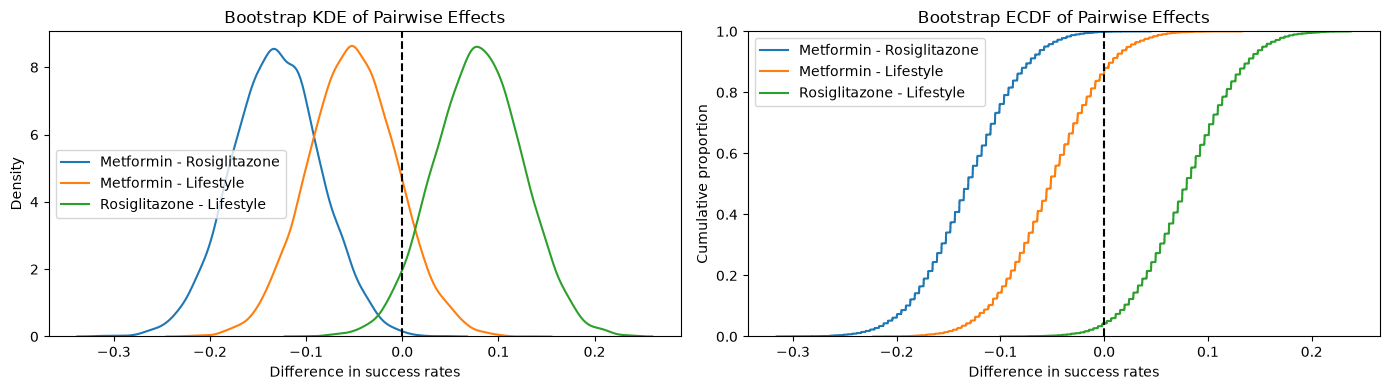

In [12]:
pairs = {
    "Metformin - Rosiglitazone": ("met", "rosi"),
    "Metformin - Lifestyle": ("met", "lifestyle"),
    "Rosiglitazone - Lifestyle": ("rosi", "lifestyle")
}

bootstrap_effects = {
    label: bootstrap_means[first] - bootstrap_means[second]
    for label, (first, second) in pairs.items()
}

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

for label, effect in bootstrap_effects.items():
    sns.kdeplot(effect, label=label, ax=ax[0])
    sns.ecdfplot(effect, label=label, ax=ax[1])

ax[0].axvline(0, color="black", linestyle="--")
ax[1].axvline(0, color="black", linestyle="--")

ax[0].set(
    title="Bootstrap KDE of Pairwise Effects",
    xlabel="Difference in success rates",
    ylabel="Density"
)
ax[1].set(
    title="Bootstrap ECDF of Pairwise Effects",
    xlabel="Difference in success rates",
    ylabel="Cumulative proportion"
)

ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

## Calculate percentile-bootstrap confidence intervals

In [13]:
ci_rows = []

for label, (first, second) in pairs.items():
    effect = bootstrap_effects[label]
    lower90, upper90 = np.quantile(effect, [0.05, 0.95])
    lower95, upper95 = np.quantile(effect, [0.025, 0.975])

    observed_difference = (
        group_summary.loc[first, "Success rate"]
        - group_summary.loc[second, "Success rate"]
    )

    ci_rows.append({
        "Comparison": label,
        "Observed difference": observed_difference,
        "90% CI": (lower90, upper90),
        "95% CI": (lower95, upper95),
        "95% CI excludes 0": lower95 > 0 or upper95 < 0
    })

ci_table = pd.DataFrame(ci_rows)
display(ci_table.round(4))

,Comparison,Observed difference,90% CI,95% CI,95% CI excludes 0
0,Metformin - Rosiglitazone,-0.1310,"(-0.2083219254106852, -0.057643924818706505)","(-0.22128949607814122, -0.04069807236939463)",True
1,Metformin - Lifestyle,-0.0514,"(-0.1285385352195697, 0.025567344532861747)","(-0.14157824933686997, 0.03901598880047156)",False
2,Rosiglitazone - Lifestyle,0.0795,"(0.0025494295880561513, 0.15646894831444186)","(-0.01032656542313192, 0.16947287333553424)",False


The effects below are the first treatment’s success rate minus the second’s. A positive difference favors the first treatment. The metformin versus rosiglitazone interval does not include zero so that difference is statistically significant at the 95% level. The rosiglitazone versus lifestyle interval excludes zero at 90% but includes it at 95%. The metformin versus lifestyle interval includes zero at both levels.

## Short report

This trial compared metformin, rosiglitazone, and lifestyle changes among 699 participants. I treated “success” as the favorable outcome. The observed success rates were 48.3% for metformin, 61.4% for rosiglitazone, and 53.4% for lifestyle changes.

Rosiglitazone had the highest observed success rate, while metformin had the lowest. The bootstrap distributions showed overlap across the three groups, although rosiglitazone’s results were shifted higher than metformin’s.

The 95% bootstrap interval for the difference between metformin and rosiglitazone was [−0.221, −0.041], which does not include zero. The intervals for metformin versus lifestyle and rosiglitazone versus lifestyle both include zero, so this analysis does not show a statistically significant difference for those comparisons at the 95% level.

Based on these results, rosiglitazone looks most promising, and its success rate was clearly higher than metformin’s in this sample. The data do not give strong enough evidence to say rosiglitazone is better than lifestyle changes. I’d treat the results as evidence for further evaluation rather than a final decision about which intervention to adopt.